# Partie 1 : Explorer et vérifier les données

In [107]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Charger Dataset :

In [108]:
df = pd.read_csv(r"tp2.csv")

df.head()

,id_operation,id_client,montant_dh,anciennete_mois,nb_ops_24h,heure,canal,appareil,region,international,resultat_enquete,fraude
0,OP02438,C10278,5396.62,90.0,6.0,11,site_web,mobile,Marrakech-Safi,non,aucune_fraude,0
1,OP00157,C10019,438.41,55.0,2.0,22,application,mobile,Souss-Massa,non,aucune_fraude,0
2,OP01987,C10604,2846.79,NaN,1.0,10,telephone,ordinateur,Casablanca-Settat,non,aucune_fraude,0
3,OP00207,C10330,914.14,127.0,4.0,7,application,mobile,Casablanca-Settat,non,aucune_fraude,0
4,OP00738,C10380,228.23,110.0,4.0,5,application,terminal,Casablanca-Settat,non,aucune_fraude,0


## Affiche les dimensions:

In [109]:
df.shape

(3045, 12)

## type des variable:

In [110]:
df.dtypes

id_operation         object
id_client            object
montant_dh          float64
anciennete_mois     float64
nb_ops_24h          float64
heure                 int64
canal                object
appareil             object
region               object
international        object
resultat_enquete     object
fraude                int64
dtype: object

## Question 2 :

In [111]:
# nombre de valeur manquante
num_valeur = df.isnull().sum()

# le porcentage des valeur manquante
porcentage = (df.isnull().mean() * 100)

# Creer un tableau 
table = pd.DataFrame({
    'Num_val_manquantes': num_valeur,
    'Porcentage (%)': porcentage
})

# Trier par porcentage en order decroissant
table = table.sort_values(
    by='Porcentage (%)',
    ascending=False
)

display(table)

,Num_val_manquantes,Porcentage (%)
canal,159,5.221675
anciennete_mois,137,4.499179
appareil,122,4.006568
montant_dh,110,3.612479
region,103,3.382594
nb_ops_24h,53,1.740558
id_operation,0,0.000000
id_client,0,0.000000
heure,0,0.000000
international,0,0.000000


## Question 3 :

In [112]:
# calculesr les doublons avec id_operation:
num_doublon = df['id_operation'].duplicated().sum()

print("Nombre des doublons: ", num_doublon)

# Supprimer les doublons :
df = df.drop_duplicates(
    subset='id_operation',
    keep='first'
)

# le nombre de lignes restante :
print("Nombre des lignes restante :", len(df))

Nombre des doublons:  45
Nombre des lignes restante : 3000


## Question 4:

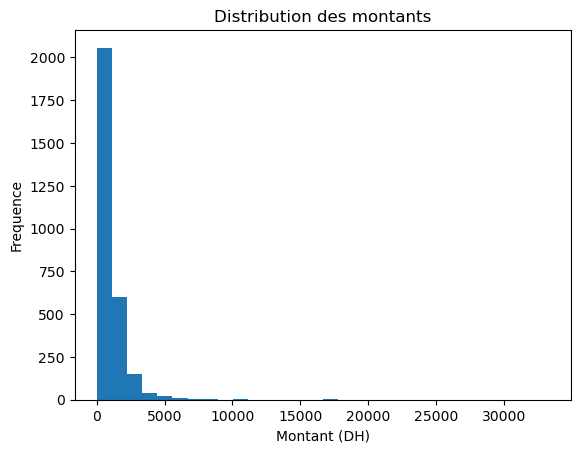

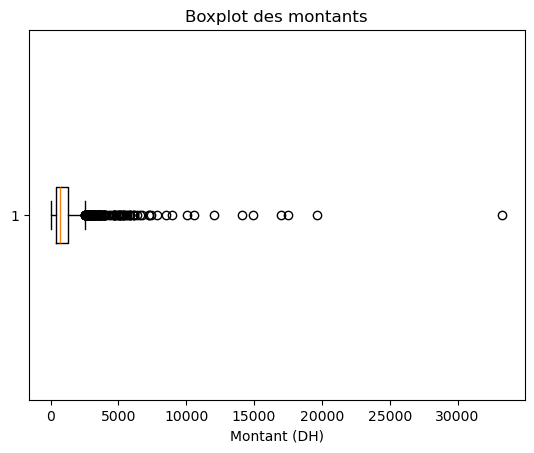

In [113]:
# Histogramme
plt.hist(df['montant_dh'].dropna(), bins=30)
plt.title("Distribution des montants")
plt.xlabel("Montant (DH)")
plt.ylabel("Frequence")
plt.show()

# Boxplot
plt.boxplot(df['montant_dh'].dropna(), vert=False)
plt.title("Boxplot des montants")
plt.xlabel("Montant (DH)")
plt.show()

## Question 5 :

Nombre de transactions normales : 2742
Nombre de fraudes : 258

Pourcentages :
fraude
0    91.4
1     8.6
Name: proportion, dtype: float64


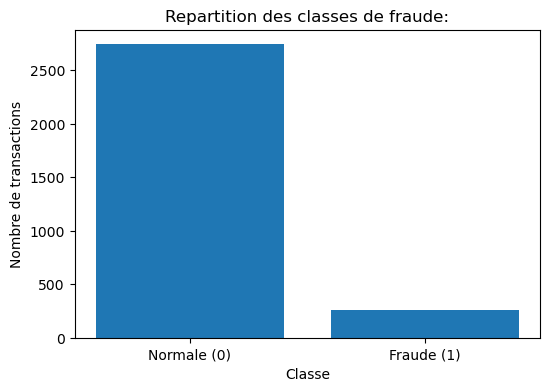

In [114]:
# Calculer les oprations de chaque classe:
counts = df['fraude'].value_counts().sort_index()

# Calculer les pourcentages
percentages = df['fraude'].value_counts(
    normalize=True
).sort_index() * 100

print("Nombre de transactions normales :", counts[0])
print("Nombre de fraudes :", counts[1])

print("\nPourcentages :")
print(percentages)

# Tracer le diagramme
plt.figure(figsize=(6, 4))

plt.bar(
    ['Normale (0)', 'Fraude (1)'],
    counts.values
)

plt.title("Repartition des classes de fraude:")
plt.xlabel("Classe")
plt.ylabel("Nombre de transactions")

plt.show()

## Question 6 :

In [115]:
# Identifier les colonnes a exclure
colonnes_exclure = [
    'id_operation',
    'id_client',
    'resultat_enquete'
]

# Créer les variables explicatives X
X = df.drop(columns=colonnes_exclure + ['fraude'])

# Définir la variable cible y
y = df['fraude']

print("Variables explicatives :")
print(X.columns.tolist())

print("\nVariable cible :")
print(y.name)

Variables explicatives :
['montant_dh', 'anciennete_mois', 'nb_ops_24h', 'heure', 'canal', 'appareil', 'region', 'international']

Variable cible :
fraude


# Partie 2 :  Préparer les données sans fuite

## Question 7 :

In [116]:
colonnes_exclure = [
    'id_operation', 
    'id_client', 
    'resultat_enquete'
]

X = df.drop(columns=colonnes_exclure + ['fraude'])
y = df['fraude']

print("Forme de X :",X.shape)
print("Forme de Y :",y.shape)

print("\nVariables explicatives :")
print(X.columns.tolist())

Forme de X : (3000, 8)
Forme de Y : (3000,)

Variables explicatives :
['montant_dh', 'anciennete_mois', 'nb_ops_24h', 'heure', 'canal', 'appareil', 'region', 'international']


## Quetion 8 :

In [117]:
from sklearn.model_selection import train_test_split

X_ref, X_ver, y_ref, y_ver = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print("Groupe de référence :", X_ref.shape)
print("Groupe de vérification :", X_ver.shape)

print("\nEffectifs dans le groupe de référence :")
print(y_ref.value_counts())

print("\nEffectifs dans le groupe de vérification :")
print(y_ver.value_counts())

print("\nProportions dans le groupe de référence :")
print(y_ref.value_counts(normalize=True) * 100)

print("\nProportions dans le groupe de vérification :")
print(y_ver.value_counts(normalize=True) * 100)

Groupe de référence : (2400, 8)
Groupe de vérification : (600, 8)

Effectifs dans le groupe de référence :
fraude
0    2194
1     206
Name: count, dtype: int64

Effectifs dans le groupe de vérification :
fraude
0    548
1     52
Name: count, dtype: int64

Proportions dans le groupe de référence :
fraude
0    91.416667
1     8.583333
Name: proportion, dtype: float64

Proportions dans le groupe de vérification :
fraude
0    91.333333
1     8.666667
Name: proportion, dtype: float64


## Question 9 :

In [118]:
num_featur = [
    'montant_dh',
    'anciennete_mois',
    'nb_ops_24h',
    'heure'
]

categ_featur = [
    'canal',
    'appareil',
    'region',
    'international'
]

print("Variables numériques :")
print(num_featur)

print("\nVariables catégorielles :")
print(categ_featur)

Variables numériques :
['montant_dh', 'anciennete_mois', 'nb_ops_24h', 'heure']

Variables catégorielles :
['canal', 'appareil', 'region', 'international']


## Question 10 :

In [119]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

num_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

X_ref_num = num_pipeline.fit_transform(X_ref[num_featur])
X_ver_num = num_pipeline.transform(X_ver[num_featur])

print("Forme référence :", X_ref_num.shape)
print("Forme vérification :", X_ver_num.shape)

Forme référence : (2400, 4)
Forme vérification : (600, 4)


## Question 11 :

In [120]:
from sklearn.preprocessing import OneHotEncoder

categ_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

X_ref_cat = categ_pipeline.fit_transform(X_ref[categ_featur])
X_ver_cat = categ_pipeline.transform(X_ver[categ_featur])

print("Forme catégorielle référence :", X_ref_cat.shape)
print("Forme catégorielle vérification :", X_ver_cat.shape)

Forme catégorielle référence : (2400, 14)
Forme catégorielle vérification : (600, 14)


## Question 12 :

In [121]:
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer(transformers=[
    ('num', num_pipeline, num_featur),
    ('cat', categ_pipeline, categ_featur)
])

X_ref_prepared = preprocessor.fit_transform(X_ref)
X_ver_prepared = preprocessor.transform(X_ver)

print("Reference    : avant", X_ref.shape, "-> apres", X_ref_prepared.shape)
print("Verification : avant", X_ver.shape, "-> apres", X_ver_prepared.shape)

Reference    : avant (2400, 8) -> apres (2400, 18)
Verification : avant (600, 8) -> apres (600, 18)


## Question 13 :

In [122]:
from sklearn.preprocessing import RobustScaler

robust_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', RobustScaler())
])

# Ajuster uniquement sur le groupe de référence
robust_pipeline.fit(X_ref[['montant_dh']])

# Deux montants à comparer
exemple = pd.DataFrame({
    'montant_dh': [1000, 30000]
})

resultat_robust = robust_pipeline.transform(exemple)

print("Montants originaux :")
display(exemple)

print("Valeurs transformées avec RobustScaler :")
print(resultat_robust)

Montants originaux :


,montant_dh
0,1000
1,30000


Valeurs transformées avec RobustScaler :
[[ 0.35422867]
 [35.87385633]]


## Question 14 :

In [123]:
fuite = pd.DataFrame({
    "médiane (référence)": X_ref[num_featur].median(),
    "médiane (toutes lignes)": X[num_featur].median(),
    "écart-type (référence)": X_ref[num_featur].std(),
    "écart-type (toutes lignes)": X[num_featur].std(),
})
display(fuite)

,médiane (référence),médiane (toutes lignes),écart-type (référence),écart-type (toutes lignes)
montant_dh,710.79,708.66,1351.544802,1320.830647
anciennete_mois,87.00,89.00,50.605183,50.850015
nb_ops_24h,3.00,3.00,1.659232,1.646029
heure,11.00,11.00,6.996928,6.996362


# Partie 3 — Comparer les méthodes de mise à l’échelle

## Question 15

In [124]:
Q1 = X_ref['montant_dh'].quantile(0.25)
Q3 = X_ref['montant_dh'].quantile(0.75)
IQR = Q3 - Q1

print("Q1 =", Q1)
print("Q3 =", Q3)
print("IQR =", IQR)

# L'IQR mesure la dispersion des 50 % des valeurs centrales.

Q1 = 393.095
Q3 = 1249.8775
IQR = 856.7825


## Question 16 :

In [125]:
# Calculer les limites
borne_inf = Q1 - 1.5 * IQR
borne_sup = Q3 + 1.5 * IQR

# Identifier les valeurs extrêmes
montants_extremes = X_ref[
    (X_ref['montant_dh'] < borne_inf) |
    (X_ref['montant_dh'] > borne_sup)
]

print("Borne inférieure :", borne_inf)
print("Borne supérieure :", borne_sup)

print("Nombre de lignes extrêmes :", len(montants_extremes))

print("\nQuelques montants extrêmes :")
display(montants_extremes[['montant_dh']].head(10))

Borne inférieure : -892.0787499999999
Borne supérieure : 2535.05125
Nombre de lignes extrêmes : 146

Quelques montants extrêmes :


,montant_dh
1601,2940.62
1348,3449.17
2660,33281.23
1489,3988.17
2049,3942.99
2088,2645.74
1105,6733.98
1074,2535.89
396,3002.07
329,5021.72


## Question 17 :

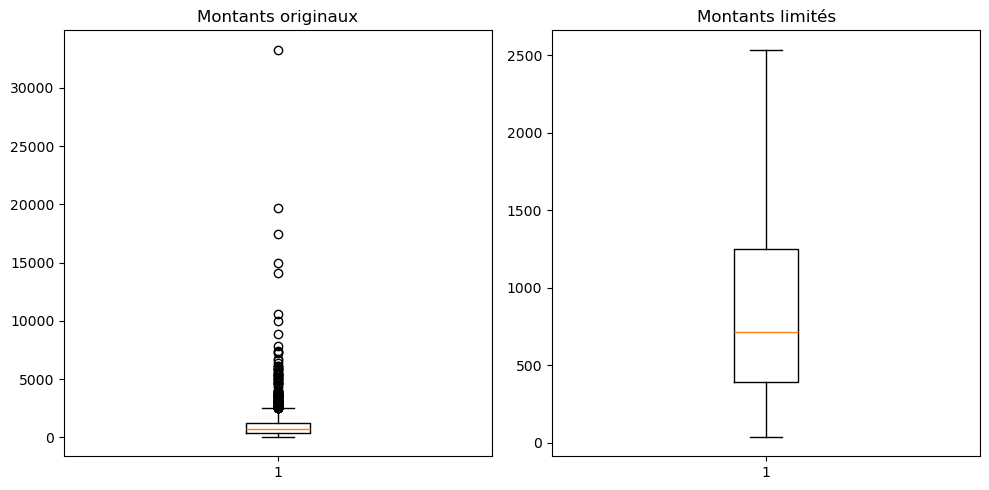

In [126]:
montants_originaux = X_ref['montant_dh'].dropna()

montants_limites = montants_originaux.clip(
    lower=borne_inf,
    upper=borne_sup
)

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.boxplot(montants_originaux)
plt.title("Montants originaux")

plt.subplot(1, 2, 2)
plt.boxplot(montants_limites)
plt.title("Montants limités")

plt.tight_layout()
plt.show()

# Le choix doit être justifié car limiter les valeurs extrêmes
# peut supprimer une information importante.

## Question 18 :

In [127]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler

minmax = MinMaxScaler()
standard = StandardScaler()
robust = RobustScaler()

X_ref_minmax = minmax.fit_transform(X_ref[['montant_dh']])
X_ver_minmax = minmax.transform(X_ver[['montant_dh']])

X_ref_standard = standard.fit_transform(X_ref[['montant_dh']])
X_ver_standard = standard.transform(X_ver[['montant_dh']])

X_ref_robust = robust.fit_transform(X_ref[['montant_dh']])
X_ver_robust = robust.transform(X_ver[['montant_dh']])

print("MinMaxScaler :", X_ver_minmax.shape)
print("StandardScaler :", X_ver_standard.shape)
print("RobustScaler :", X_ver_robust.shape)

MinMaxScaler : (600, 1)
StandardScaler : (600, 1)
RobustScaler : (600, 1)


## Question 19 :

In [128]:
montants = [
    500,
    1000,
    1500,
    X_ver['montant_dh'].max()
]

valeurs = pd.DataFrame({'montant_dh': montants})

valeurs['MinMaxScaler'] = minmax.transform(valeurs[['montant_dh']]).ravel()
valeurs['StandardScaler'] = standard.transform(valeurs[['montant_dh']]).ravel()
valeurs['RobustScaler'] = robust.transform(valeurs[['montant_dh']]).ravel()

valeurs

,montant_dh,MinMaxScaler,StandardScaler,RobustScaler
0,500.00,0.013945,-0.394055,-0.246025
1,1000.00,0.028985,-0.024028,0.337554
2,1500.00,0.044025,0.345999,0.921132
3,16962.99,0.509149,11.789449,18.968875


## Question 20 : 

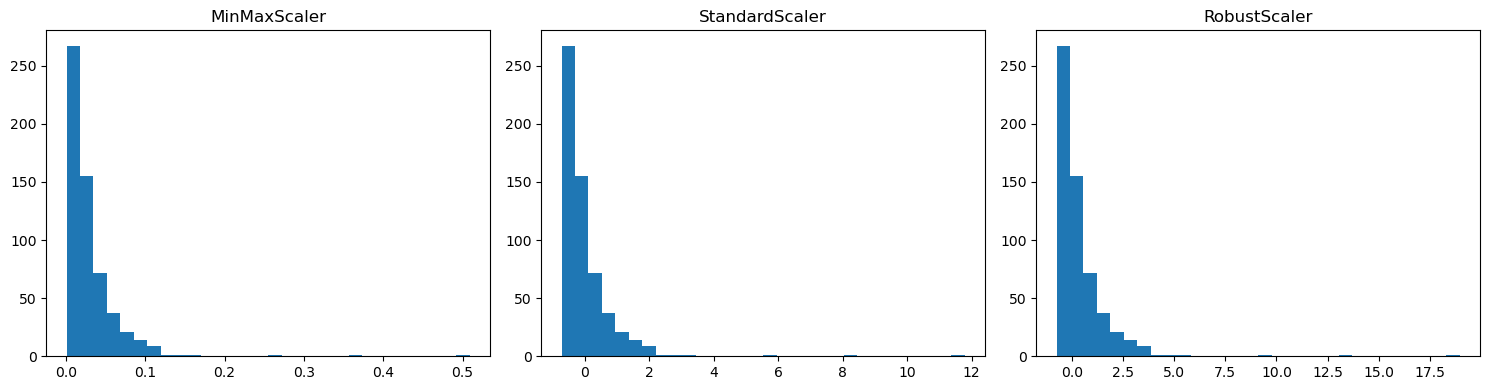

In [129]:
plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
plt.hist(X_ver_minmax.flatten(), bins=30)
plt.title("MinMaxScaler")

plt.subplot(1, 3, 2)
plt.hist(X_ver_standard.flatten(), bins=30)
plt.title("StandardScaler")

plt.subplot(1, 3, 3)
plt.hist(X_ver_robust.flatten(), bins=30)
plt.title("RobustScaler")

plt.tight_layout()
plt.show()

## Question 21 :

In [130]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

scaler.fit(X_ref[['montant_dh']])

max_reference = X_ref['montant_dh'].max()
nouveau_montant = max_reference + 1000

valeur_transformee = scaler.transform(
    pd.DataFrame({'montant_dh': [nouveau_montant]})
)

print("Maximum du groupe de référence :", max_reference)
print("Nouveau montant :", nouveau_montant)
print("Valeur transformée :", valeur_transformee[0][0])

# Oui, la valeur transformée peut dépasser 1
# si le nouveau montant dépasse le maximum du groupe de référence.

Maximum du groupe de référence : 33281.23
Nouveau montant : 34281.23
Valeur transformée : 1.030079874097679


# Partie 4 — Préparer des classes déséquilibrées

## Quetion 22 : 

In [131]:
effectifs = y_ref.value_counts()

print("Nombre de transactions normales :", effectifs[0])
print("Nombre de fraudes :", effectifs[1])

rapport = effectifs[0] / effectifs[1]

print("Rapport entre les deux classes :", rapport)

Nombre de transactions normales : 2194
Nombre de fraudes : 206
Rapport entre les deux classes : 10.650485436893204


## Question 23 :

In [132]:
from imblearn.over_sampling import RandomOverSampler

ros = RandomOverSampler(random_state=42)

X_over, y_over = ros.fit_resample(X_ref, y_ref)

print("Avant surechantillonnage :")
print(y_ref.value_counts())

print("\nApres surechantillonnage :")
print(y_over.value_counts())

print("\nNombre de lignes avant :", len(X_ref))
print("Nombre de lignes apres :", len(X_over))

# Les nouvelles lignes sont des copies de lignes existantes.

Avant surechantillonnage :
fraude
0    2194
1     206
Name: count, dtype: int64

Apres surechantillonnage :
fraude
0    2194
1    2194
Name: count, dtype: int64

Nombre de lignes avant : 2400
Nombre de lignes apres : 4388


# Question 24 :

In [133]:
from imblearn.under_sampling import RandomUnderSampler

rus = RandomUnderSampler(random_state=42)

X_under, y_under = rus.fit_resample(X_ref, y_ref)

print("Avant sous-échantillonnage :")
print(y_ref.value_counts())

print("\nAprès sous-échantillonnage :")
print(y_under.value_counts())

print("\nNombre de lignes conservées :", len(X_under))
print("Nombre de lignes supprimées :", len(X_ref) - len(X_under))

# Le risque est de perdre des informations en supprimant
# un grand nombre de transactions normales.

Avant sous-échantillonnage :
fraude
0    2194
1     206
Name: count, dtype: int64

Après sous-échantillonnage :
fraude
0    206
1    206
Name: count, dtype: int64

Nombre de lignes conservées : 412
Nombre de lignes supprimées : 1988


## Question 25 :

In [134]:
A = np.array([2, 4])
B = np.array([4, 8])

lambda_ = 0.5

C = A + lambda_ * (B - A)

print("Observation A :", A)
print("Observation B :", B)
print("Observation synthetique C :", C)

# C est une nouvelle observation créée entre A et B.
# SMOTE crée des observations synthétiques et ne fait pas
# simplement des copies des observations existantes.

Observation A : [2 4]
Observation B : [4 8]
Observation synthetique C : [3. 6.]


## Questions 26 :

SMOTE appliqué aux catégories encodées en OneHotEncoder
peut produire des valeurs intermédiaires non valides
pour les catégories.

La méthode adaptée aux données numériques et catégorielles
est SMOTENC.

## Question 27

In [135]:
tableau_comparaison = pd.DataFrame({
    'Avant rééquilibrage': y_ref.value_counts(),
    'Après RandomOverSampler': y_over.value_counts(),
    'Après RandomUnderSampler': y_under.value_counts()
})

display(tableau_comparaison)

print("\nGroupe de vérification :")
print(y_ver.value_counts())

# Le groupe de vérification ne doit pas être rééquilibré.
# Il doit conserver sa distribution initiale.

,Avant rééquilibrage,Après RandomOverSampler,Après RandomUnderSampler
fraude,,,
0,2194,2194,206
1,206,2194,206



Groupe de vérification :
fraude
0    548
1     52
Name: count, dtype: int64


# Partie 5 : Vérifier et enregistrer les données préparées

## Question 28 :

In [136]:
from sklearn.preprocessing import RobustScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

num_pipeline_final = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', RobustScaler())
])

categ_pipeline_final = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor_final = ColumnTransformer(transformers=[
    ('num', num_pipeline_final, num_featur),
    ('cat', categ_pipeline_final, categ_featur)
])

## Question 29 :

In [137]:
from scipy import sparse

X_ref_final = preprocessor_final.fit_transform(X_ref)
X_ver_final = preprocessor_final.transform(X_ver)

print("Dimensions du groupe de référence :", X_ref_final.shape)
print("Dimensions du groupe de vérification :", X_ver_final.shape)

if sparse.issparse(X_ref_final):
    print("Valeurs manquantes référence :", np.isnan(X_ref_final.data).sum())
else:
    print("Valeurs manquantes référence :", np.isnan(X_ref_final).sum())

if sparse.issparse(X_ver_final):
    print("Valeurs manquantes vérification :", np.isnan(X_ver_final.data).sum())
else:
    print("Valeurs manquantes vérification :", np.isnan(X_ver_final).sum())

Dimensions du groupe de référence : (2400, 18)
Dimensions du groupe de vérification : (600, 18)
Valeurs manquantes référence : 0
Valeurs manquantes vérification : 0


## Question 30 : 

In [138]:
nouvelle_transaction = X_ref.iloc[[0]].copy()

nouvelle_transaction['canal'] = '__INCONNU__'

transaction_transformee = preprocessor_final.transform(
    nouvelle_transaction
)
print("Transformation réussie :")
display(transaction_transformee)

# handle_unknown='ignore' permet de transformer
# une nouvelle catégorie sans provoquer une erreur.

Transformation réussie :


array([[-0.35673954, -0.4047619 ,  0.        ,  0.38461538,  0.        ,
         0.        ,  0.        ,  0.        ,  1.        ,  0.        ,
         0.        ,  0.        ,  0.        ,  1.        ,  0.        ,
         0.        ,  0.        ,  1.        ]])

## Question 31 :

In [139]:
import joblib

joblib.dump(preprocessor_final, 'preprocessor_final.pkl')

preprocessor_charge = joblib.load('preprocessor_final.pkl')

echantillon = X_ref.iloc[:5]

resultat_original = preprocessor_final.transform(echantillon)
resultat_charge = preprocessor_charge.transform(echantillon)

if sparse.issparse(resultat_original):
    comparaison = np.allclose(
        resultat_original.toarray(),
        resultat_charge.toarray()
    )
else:
    comparaison = np.allclose(resultat_original, resultat_charge)

print("Résultats identiques :", comparaison)

Résultats identiques : True


## Question 32 :

In [140]:
print("====> BILAN DU TP")

print("\n1. Nombre de doublons supprimés : 45")

print("\n2. Valeurs manquantes traitées :")
display(df.isnull().sum())

print("\n3. Valeurs extrêmes observées :")
print("Borne inférieure :", borne_inf)
print("Borne supérieure :", borne_sup)
print("Nombre de valeurs extrêmes :", len(montants_extremes))

print("\n4. Méthodes de transformation choisies :")
print("- Variables numériques : médiane + RobustScaler")
print("- Variables catégorielles : valeur la plus fréquente + OneHotEncoder")

print("\n5. Effet du rééquilibrage :")
print("RandomOverSampler : augmente la classe minoritaire.")
print("RandomUnderSampler : réduit la classe majoritaire.")
print("SMOTE : crée des observations synthétiques.")

print("\n6. Groupe de vérification :")
print("Il reste inchangé et n'est pas rééquilibré.")

====> BILAN DU TP

1. Nombre de doublons supprimés : 45

2. Valeurs manquantes traitées :


id_operation          0
id_client             0
montant_dh          107
anciennete_mois     135
nb_ops_24h           53
heure                 0
canal               156
appareil            120
region              102
international         0
resultat_enquete      0
fraude                0
dtype: int64


3. Valeurs extrêmes observées :
Borne inférieure : -892.0787499999999
Borne supérieure : 2535.05125
Nombre de valeurs extrêmes : 146

4. Méthodes de transformation choisies :
- Variables numériques : médiane + RobustScaler
- Variables catégorielles : valeur la plus fréquente + OneHotEncoder

5. Effet du rééquilibrage :
RandomOverSampler : augmente la classe minoritaire.
RandomUnderSampler : réduit la classe majoritaire.
SMOTE : crée des observations synthétiques.

6. Groupe de vérification :
Il reste inchangé et n'est pas rééquilibré.


# Travail complémentaire

## Bonus A — Comparer l’imputation par la moyenne et par la mediane

In [144]:
base = X_ref["montant_dh"].dropna()
avec_extreme = pd.concat([base, pd.Series([5_000_000.0])], ignore_index=True)   # un montant aberrant ajouté

res = pd.DataFrame({
    "sans montant aberrant": [base.mean(), base.median()],
    "avec 1 montant de 5 000 000 DH": [avec_extreme.mean(), avec_extreme.median()],
}, index=["moyenne", "médiane"])
res["variation (%)"] = (res.iloc[:, 1] / res.iloc[:, 0] - 1) * 100
display(res)
print(f"Sur les données réelles, la moyenne ({base.mean():,.2f}) est bien supérieure à la médiane ({base.median():,.2f}) : "
      "les montants élevés tirent la moyenne vers le haut.")

,sans montant aberrant,avec 1 montant de 5 000 000 DH,variation (%)
moyenne,1032.467777,3193.716169,209.328411
médiane,710.790000,711.290000,0.070344


Sur les données réelles, la moyenne (1,032.47) est bien supérieure à la médiane (710.79) : les montants élevés tirent la moyenne vers le haut.


## Bonus B — Tester SMOTENC sur des variable numerique et categorielle

In [145]:
d3 = X_ref[["montant_dh", "nb_ops_24h", "canal", "international"]].copy()
d3[["montant_dh", "nb_ops_24h"]] = d3[["montant_dh", "nb_ops_24h"]].fillna(d3[["montant_dh", "nb_ops_24h"]].median())

for c in ["canal", "international"]:
    d3[c] = d3[c].fillna(d3[c].mode()[0])       

smotenc = SMOTENC(categorical_features=[2, 3], random_state=42)  
d3_sm, y3_sm = smotenc.fit_resample(d3, y_ref)
synth3 = d3_sm.iloc[len(d3):]

print("Classes avant :", {int(k): int(v) for k, v in y_ref.value_counts().sort_index().items()}, "| après :", {int(k): int(v) for k, v in pd.Series(y3_sm).value_counts().sort_index().items()})
display(synth3.head(8))

for c in ["canal", "international"]:
    print(f"{c:14s} catégories avant : {sorted(d3[c].unique())} | dans les lignes synthétiques : {sorted(synth3[c].unique())}")
    
print("Aucune catégorie inventée :", all(set(synth3[c]) <= set(d3[c]) for c in ["canal", "international"]))

Classes avant : {0: 2194, 1: 206} | après : {0: 2194, 1: 2194}


,montant_dh,nb_ops_24h,canal,international
2400,1101.169662,3.000000,telephone,non
2401,2127.940598,1.558304,site_web,non
2402,234.816687,2.605287,application,non
2403,280.264161,5.000000,site_web,non
2404,219.388111,2.482969,agence,oui
2405,2129.328904,2.133480,application,non
2406,692.286256,1.000000,telephone,oui
2407,576.581483,1.727939,site_web,non


canal          catégories avant : ['agence', 'application', 'site_web', 'telephone'] | dans les lignes synthétiques : ['agence', 'application', 'site_web', 'telephone']
international  catégories avant : ['non', 'oui'] | dans les lignes synthétiques : ['non', 'oui']
Aucune catégorie inventée : True
